# 2. Output Budget

The problem of notebook 1, learned by an algorithm in which each unit owns its incoming connections and the output
holds the whole budget.

**Algorithm.** `algorithms.OutputBudget`. Each LTU has `LTU_INPUTS` connections from x. A new LTU gets random weights
on `RANDOM_LTU_INPUTS` of them, at a step size of 0.03, and weight 0 on the others, at a step size of 1e-4. The
output pays for its own connections and for each LTU: `LTU_INPUTS` + 1 connections, with the output's connection to
it. Half of the connections that the output frees go to its new connections, and half go to new LTUs.
`prune_connections` is the sign rule of notebook 1, on the LTUs and on the output, every 10k steps. An LTU that the
output stops reading is removed. `add_connections` refills each LTU's free slots with uniform draws from x, and the
output reads uniform draws from x and the LTUs.

`algorithms.SoftCandidates` is the same, except that a new LTU starts all its inputs as soft candidates: weights
from U(-1e-4, 1e-4), at a step size of 1e-4.

**Baselines.** The full search of notebook 1, with its two ways to count the budget: `CountAllConnections` and
`CountCandidates`.

5 seeds.

In [1]:
import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
import jax
jax.config.update('jax_platforms', 'cuda')

from phd.sandbox.unit_search.algorithm import experiment, problems
from phd.sandbox.unit_search.connection_slots import algorithms

assert jax.default_backend() == 'gpu'
%matplotlib inline

In [2]:
N_INPUTS = 100
N_TARGET_LTUS = 16
INPUTS_PER_TARGET_LTU = 4

MAX_CONNECTIONS = 2048
LTU_INPUTS = 30
RANDOM_LTU_INPUTS = 15

# The baselines of notebook 1
MAX_LTUS = 256
INITIAL_LTU_CONNECTIONS = 20
INITIAL_LTU_COUNT = min((MAX_CONNECTIONS - N_INPUTS) // (INITIAL_LTU_CONNECTIONS + 1), MAX_LTUS)
CANDIDATES_LTU_COUNT = min((MAX_CONNECTIONS - N_INPUTS) // (N_INPUTS + 1), MAX_LTUS)

LEARNING_STEPS = 200_000

connection and unit search (baseline): RMSE over the last 10% 0.392 ; at the end, 143 LTUs and 2039 connections in the budget (21s)


candidates in the budget (baseline): RMSE over the last 10% 1.299 ; at the end, 19 LTUs and 2019 connections in the budget (22s)


output budget (proposed): RMSE over the last 10% 1.205 ; at the end, 59 LTUs and 1927 connections in the budget (15s)


output budget, soft candidates (proposed): RMSE over the last 10% 2.415 ; at the end, 59 LTUs and 1923 connections in the budget (15s)


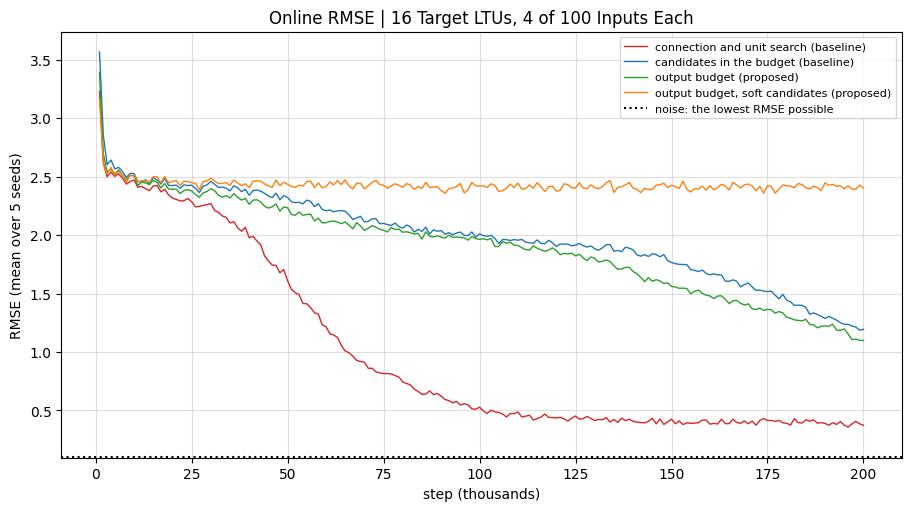

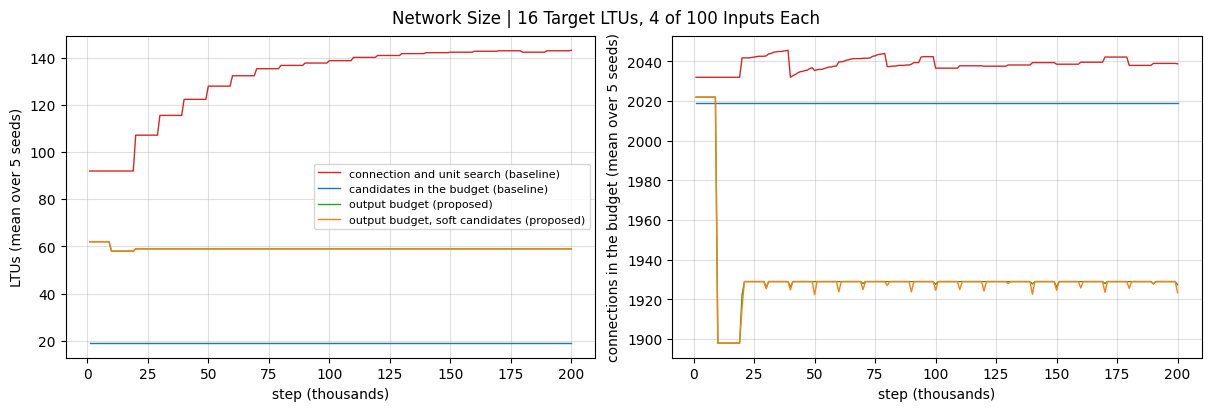

In [3]:
problem = problems.SignLTUTarget(
    n_inputs = N_INPUTS,
    n_target_ltus = N_TARGET_LTUS,
    fan_in = INPUTS_PER_TARGET_LTU,
)
baseline_sizes = dict(
    n_inputs = problem.n_inputs,
    n_outputs = problem.n_outputs,
    width = INITIAL_LTU_COUNT,
    max_ltus = MAX_LTUS,
    budget = MAX_CONNECTIONS,
    initial_fan_in = INITIAL_LTU_CONNECTIONS,
)
methods = {
    'connection and unit search (baseline)': algorithms.CountAllConnections(**baseline_sizes),
    'candidates in the budget (baseline)': algorithms.CountCandidates(
        **baseline_sizes | dict(width=CANDIDATES_LTU_COUNT)),
    'output budget (proposed)': algorithms.OutputBudget(
        n_inputs = problem.n_inputs,
        n_outputs = problem.n_outputs,
        max_ltus = MAX_CONNECTIONS // (LTU_INPUTS + 1),
        budget = MAX_CONNECTIONS,
        initial_fan_in = LTU_INPUTS,
        n_random_weights = RANDOM_LTU_INPUTS,
    ),
    'output budget, soft candidates (proposed)': algorithms.SoftCandidates(
        n_inputs = problem.n_inputs,
        n_outputs = problem.n_outputs,
        max_ltus = MAX_CONNECTIONS // (LTU_INPUTS + 1),
        budget = MAX_CONNECTIONS,
        initial_fan_in = LTU_INPUTS,
    ),
}
rmse, records = experiment.run(methods, problem, steps=LEARNING_STEPS, cache_dir='cache')
title = f'{N_TARGET_LTUS} Target LTUs, {INPUTS_PER_TARGET_LTU} of {N_INPUTS} Inputs Each'
experiment.plot(rmse, problem, f'Online RMSE | {title}')
experiment.plot_sizes(records, f'Network Size | {title}')

## The |w| + |h| rule

The same methods, with the connection pruning of `algorithms.Sifting` in place of the sign rule: the CI rule of
`../../feature_sifting/networks/parallel_mnist_label_changes.ipynb`. Every step, it cuts each connection of the LTUs
and the output whose |w| + |h| is below the bound for a dead weight of the same age and step size. The baselines are
the same as above.

connection and unit search (baseline): RMSE over the last 10% 0.392 ; at the end, 143 LTUs and 2039 connections in the budget (cached)
candidates in the budget (baseline): RMSE over the last 10% 1.299 ; at the end, 19 LTUs and 2019 connections in the budget (cached)


output budget, |w| + |h| rule (proposed): RMSE over the last 10% 2.638 ; at the end, 65 LTUs and 2038 connections in the budget (34s)


output budget, soft candidates, |w| + |h| rule (proposed): RMSE over the last 10% 2.662 ; at the end, 65 LTUs and 2038 connections in the budget (34s)


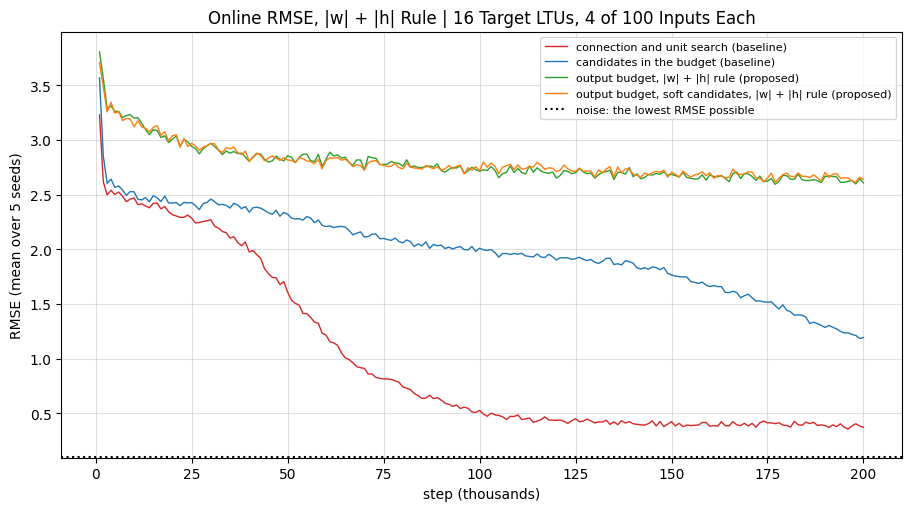

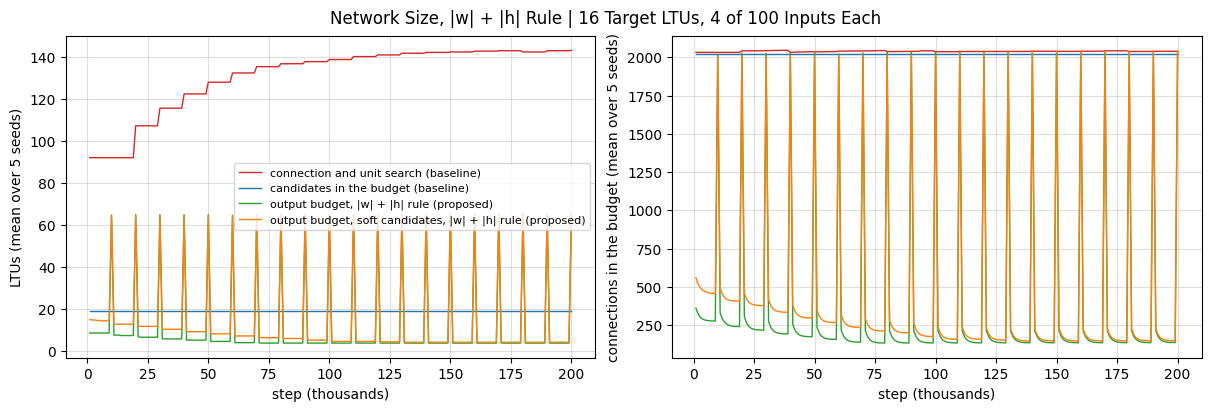

In [4]:
sifting_methods = {label: method for label, method in methods.items() if '(baseline)' in label} | {
    'output budget, |w| + |h| rule (proposed)': algorithms.Sifting(
        n_inputs = problem.n_inputs,
        n_outputs = problem.n_outputs,
        max_ltus = MAX_CONNECTIONS // (LTU_INPUTS + 1),
        budget = MAX_CONNECTIONS,
        initial_fan_in = LTU_INPUTS,
        n_random_weights = RANDOM_LTU_INPUTS,
    ),
    'output budget, soft candidates, |w| + |h| rule (proposed)': algorithms.SiftingSoftCandidates(
        n_inputs = problem.n_inputs,
        n_outputs = problem.n_outputs,
        max_ltus = MAX_CONNECTIONS // (LTU_INPUTS + 1),
        budget = MAX_CONNECTIONS,
        initial_fan_in = LTU_INPUTS,
    ),
}
sifting_rmse, sifting_records = experiment.run(sifting_methods, problem, steps=LEARNING_STEPS, cache_dir='cache')
experiment.plot(sifting_rmse, problem, f'Online RMSE, |w| + |h| Rule | {title}')
experiment.plot_sizes(sifting_records, f'Network Size, |w| + |h| Rule | {title}')